In [1]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('WineQT.csv')
df = df.drop(columns=['Id'])
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6


In [3]:
le = LabelEncoder()
df_enc = df.copy()
df_enc['quality'] = le.fit_transform(df['quality'])

In [4]:
x = df_enc.drop(columns=['quality'])
y = df_enc['quality']

model = GaussianNB()
model.fit(x, y)

GaussianNB()

In [5]:
# Order: fixed acidity, volatile acidity, citric acid, residual sugar, chlorides,
#        free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol
test = [
    [7.4, 0.70, 0.00, 1.9, 0.076, 11, 34, 0.9978, 3.51, 0.56, 9.4],
    [8.5, 0.28, 0.56, 1.8, 0.092, 35, 103, 0.9969, 3.30, 0.75, 10.5],
    [7.9, 0.35, 0.46, 3.6, 0.078, 15, 37, 0.9973, 3.35, 0.86, 12.8]
]

print("\n----prediction------------------------")
for i, t in enumerate(test, 1):
    row = pd.DataFrame([t], columns=x.columns)
    pred = le.inverse_transform(model.predict(row))[0]
    prob = model.predict_proba(row)[0]
    print(f"Test Case {i}: Alcohol={t[10]}, Volatile Acidity={t[1]}, pH={t[8]}, Sulphates={t[9]}")
    print(f"Result: Wine Quality -> {pred}")
    for cls, p in zip(le.classes_, prob):
        print(f"p(quality={cls}) = {p:.4f}")
    print()


----prediction------------------------
Test Case 1: Alcohol=9.4, Volatile Acidity=0.7, pH=3.51, Sulphates=0.56
Result: Wine Quality -> 5
p(quality=3) = 0.0524
p(quality=4) = 0.0387
p(quality=5) = 0.6011
p(quality=6) = 0.3075
p(quality=7) = 0.0003
p(quality=8) = 0.0000

Test Case 2: Alcohol=10.5, Volatile Acidity=0.28, pH=3.3, Sulphates=0.75
Result: Wine Quality -> 5
p(quality=3) = 0.0000
p(quality=4) = 0.0006
p(quality=5) = 0.4924
p(quality=6) = 0.1247
p(quality=7) = 0.3822
p(quality=8) = 0.0001

Test Case 3: Alcohol=12.8, Volatile Acidity=0.35, pH=3.35, Sulphates=0.86
Result: Wine Quality -> 7
p(quality=3) = 0.0000
p(quality=4) = 0.0002
p(quality=5) = 0.0002
p(quality=6) = 0.1795
p(quality=7) = 0.5203
p(quality=8) = 0.2998



In [6]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 56.87%


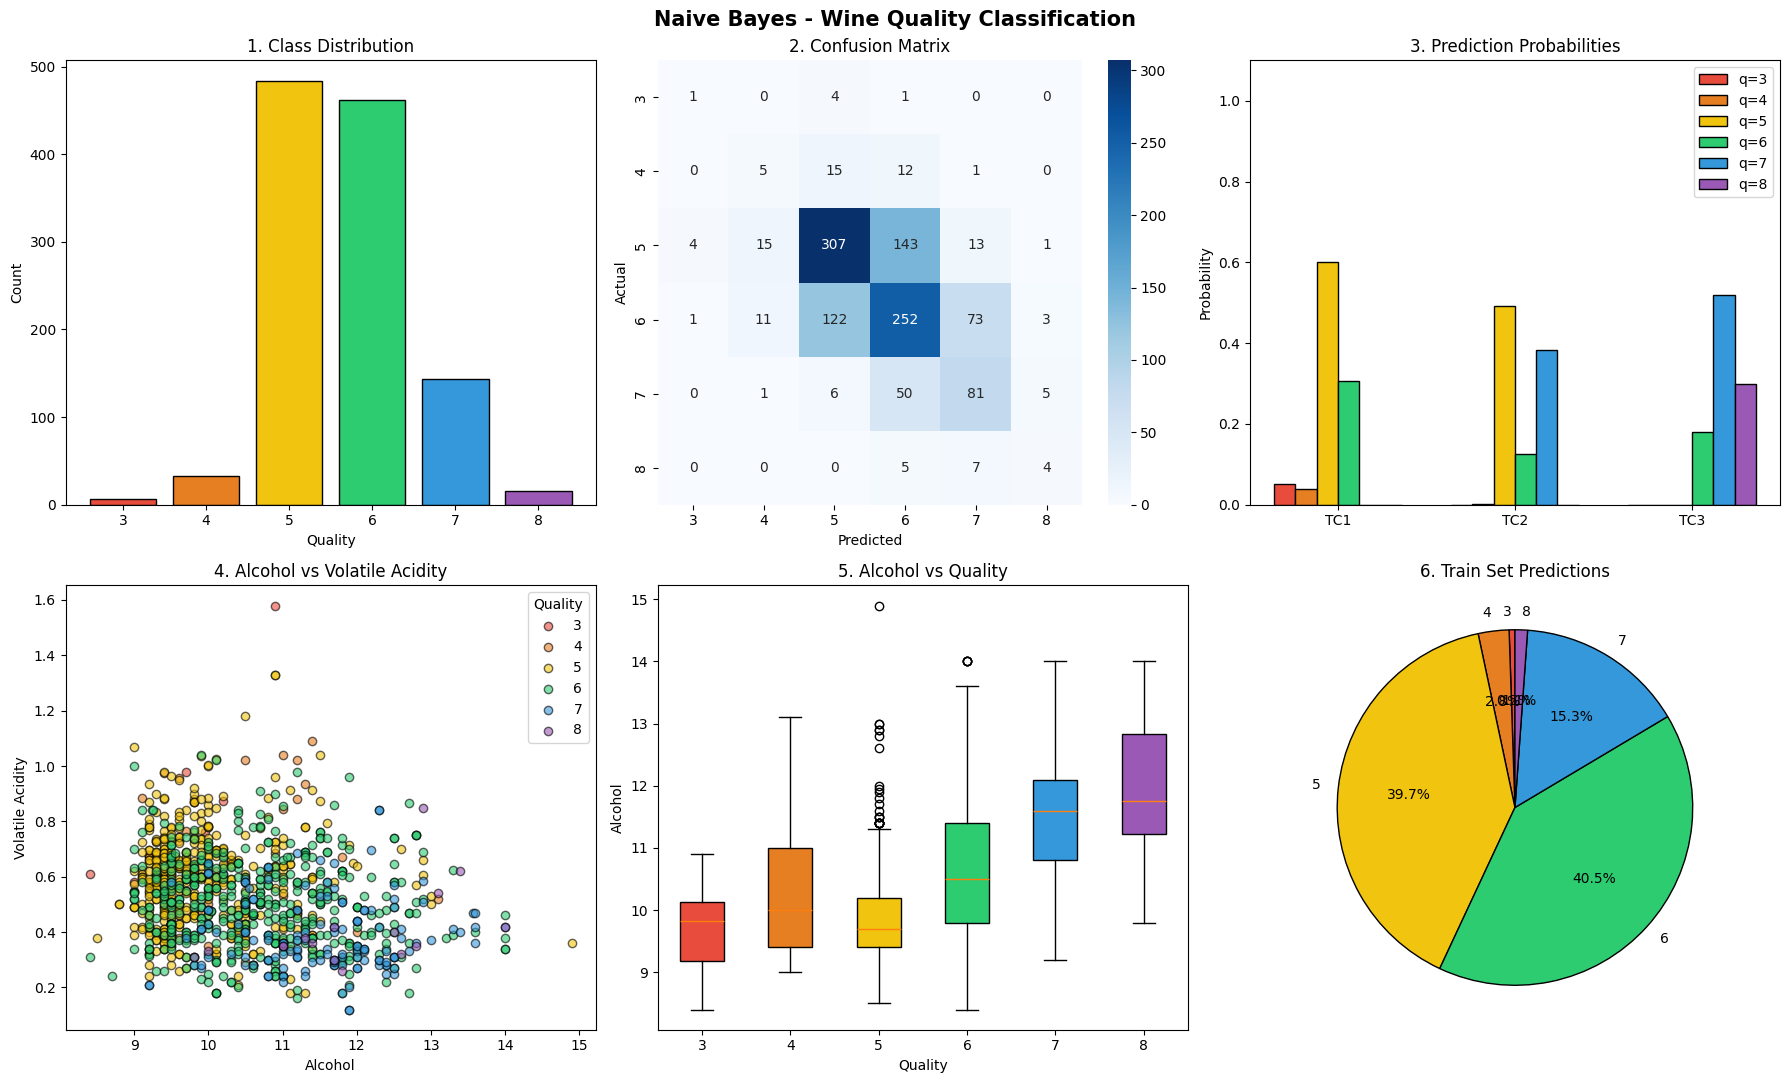

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#3498db', '#9b59b6']

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Wine Quality Classification", fontsize=15, fontweight="bold")

# 1. Class Distribution
counts = df['quality'].value_counts().sort_index()
axes[0,0].bar(counts.index.astype(str), counts.values, color=colors, edgecolor='black')
axes[0,0].set_title("1. Class Distribution")
axes[0,0].set_xlabel("Quality")
axes[0,0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[0,1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0,1].set_title("2. Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_axis = np.arange(len(tc_labels))
width = 0.12
probs = np.array([model.predict_proba(pd.DataFrame([t], columns=x.columns))[0] for t in test])

for i, cls in enumerate(le.classes_):
    axes[0,2].bar(x_axis + (i-2.5)*width, probs[:, i], width,
                  label=f'q={cls}', color=colors[i], edgecolor='black')
axes[0,2].set_title("3. Prediction Probabilities")
axes[0,2].set_xticks(x_axis)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4. Alcohol vs Volatile Acidity
for q, c in zip(le.classes_, colors):
    s = df[df['quality'] == q]
    axes[1,0].scatter(s['alcohol'], s['volatile acidity'], label=q, color=c,
                      edgecolor='black', alpha=0.6)
axes[1,0].set_title("4. Alcohol vs Volatile Acidity")
axes[1,0].set_xlabel("Alcohol")
axes[1,0].set_ylabel("Volatile Acidity")
axes[1,0].legend(title="Quality")

# 5. Alcohol by Quality (Box Plot)
data_box = [df[df['quality'] == q]['alcohol'] for q in le.classes_]
bp = axes[1,1].boxplot(data_box, patch_artist=True)
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c)
axes[1,1].set_xticklabels(le.classes_)
axes[1,1].set_title("5. Alcohol vs Quality")
axes[1,1].set_xlabel("Quality")
axes[1,1].set_ylabel("Alcohol")

# 6. Pie Chart
pred_counts = pd.Series(y_pred).value_counts().sort_index()
pred_counts.index = le.inverse_transform(pred_counts.index)
axes[1,2].pie(pred_counts, labels=pred_counts.index, colors=colors[:len(pred_counts)],
              autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Train Set Predictions")

plt.tight_layout()
plt.show()